# 01 - Data export (Sentinel-1 monthly image + Dynamic World monthly label)

For every site in the `SITES` list below, this notebook downloads, for each month:
- **radar**: per-pixel median of that month's Sentinel-1 scenes (VV, VH in dB)
- **label**: Dynamic World class with the highest *month-averaged* probability
- **conf**: that highest averaged probability (how sure the label is)
- **n_scenes**: how many radar scenes went into the month
- **pass_dir**: which orbit direction was used (one per site, whichever has more scenes)

Each month is saved as `data/<site>_<year>-<month>.npz`. A pixel with no valid label is `255` (the ignore value).
Re-running skips months that are already saved, so an interrupted run just continues.

Before running: you need an Earth Engine account and a Google Cloud project registered for it.

## 1. Settings (edit these)

In [ ]:
PROJECT = "deep-learning-project-512013"   # your Google Cloud project registered for Earth Engine
YEAR = 2024                       # the year every site gets (validation and test sites get only this one)
EXTRA_YEARS = [2022, 2023, 2025]   # extra years for training sites only: more data and more weather
WORKERS = 6                       # Earth Engine requests in flight at once (1 = one at a time); about 5x faster with 6-8
MONTHS = range(1, 13)
SIZE_PX = 1000                # 1000 px x 10 m = 10 km square
SCALE = 10                    # metres per pixel (Sentinel-1 and Dynamic World are both 10 m)

# name, latitude, longitude, role. Proposed list, edit freely. Coordinates are approximate: check each on a map.
SITES = [
    ("kisumu",           -0.0917,  34.7680, "train"),
    ("morogoro",         -6.8210,  37.6615, "train"),
    ("ilorin",            8.4966,   4.5421, "train"),
    ("raipur",           21.2514,  81.6296, "train"),
    ("mymensingh",       24.7471,  90.4203, "train"),
    ("battambang",       13.0957, 103.2022, "train"),
    ("mzuzu",           -11.4656,  34.0207, "val"),
    ("warangal",         17.9689,  79.5941, "val"),
    ("bobo_dioulasso",   11.1771,  -4.2979, "test"),
    ("nashik",           19.9975,  73.7898, "test"),
    # rural sites found by the screening in section 9 (built share under 15%, fully labelled)
    ("kwara_rural",       8.0500,   4.1000, "train"),
    ("kilombero",        -8.3821,  36.4348, "train"),
    ("haor",             24.8171,  91.6486, "train"),
    ("chhattisgarh",     20.5326,  81.4656, "val"),
    ("e_zambia",        -13.6391,  32.3958, "val"),
    ("n_ghana",           9.6552,  -1.0924, "test"),
    # dry-region town centres (OpenStreetMap Nominatim, city level). Their rural squares are found in section 10.
    ("dodoma",          -6.1791,  35.7468, "train"),   # Tanzania, semi-arid central plateau
    ("kitui",           -1.3666,  38.0166, "train"),   # Kenya, semi-arid east
    ("solapur",         17.6700,  75.9008, "train"),   # India, dry Deccan plateau
    ("pakokku",         21.3343,  95.0944, "train"),   # Myanmar, Dry Zone
    ("khon_kaen",       16.4304, 102.8356, "train"),   # Thailand, seasonally dry north-east
    ("adama",            8.5440,  39.2705, "train"),   # Ethiopia, Rift Valley
    ("dodoma_rural",  -5.9291,  35.4968, "train"),
    ("kitui_rural",  -1.6166,  38.0166, "train"),
    ("solapur_rural",    17.92,  76.1508, "train"),
    ("pakokku_rural",  21.0843,  94.8444, "train"),
    ("khon_kaen_rural",  16.1804, 102.5856, "train"),
    ("adama_rural",    8.294,  39.0205, "train")
]


def years_for(role):
    """Every site gets YEAR; training sites also get the extra years."""
    return [YEAR] + (EXTRA_YEARS if role == "train" else [])

In [14]:
print(len(SITES))

28


## 2. Connect to Earth Engine

In [12]:
import os
import ee
import numpy as np
import matplotlib.pyplot as plt

try:
    ee.Initialize(project=PROJECT)
except Exception:
    # ask only for the Earth Engine permission, matching the single box ticked on the consent page
    ee.Authenticate(scopes=["https://www.googleapis.com/auth/earthengine"])
    ee.Initialize(project=PROJECT)

## 3. Helper functions

- `month_range` gives the start and end dates of one month.
- `pick_pass` chooses the orbit direction (ascending or descending) with more scenes at a site, so we never mix directions.
- `radar_month` builds the month's median radar image and counts the scenes.
- `label_month` averages Dynamic World's class probabilities over the month and picks the top class.
- `make_grid` builds the square pixel grid around a site.
- `download` pulls an Earth Engine image into a NumPy array for that grid.

In [13]:
import io
import json

CLASSES = ["water", "trees", "grass", "flooded_vegetation", "crops",
           "shrub_and_scrub", "built", "bare", "snow_and_ice"]   # index in this list = label value
NODATA_LABEL = 255
NODATA_RADAR = -999.0


def month_range(year, month):
    """Start (inclusive) and end (exclusive) dates of one month."""
    start = ee.Date.fromYMD(year, month, 1)
    return start, start.advance(1, "month")


def pick_pass(region, year):
    """Orbit direction with the most Sentinel-1 scenes over the site in that year, or None if there are none.
    Some places are only covered from one direction, and mixing directions changes how things look."""
    s1 = (ee.ImageCollection("COPERNICUS/S1_GRD").filterBounds(region)
          .filterDate(f"{year}-01-01", f"{year + 1}-01-01")
          .filter(ee.Filter.eq("instrumentMode", "IW")))
    counts = s1.aggregate_histogram("orbitProperties_pass").getInfo()
    return max(counts, key=counts.get) if counts else None


def radar_month(region, start, end, pass_dir):
    """Median of all Sentinel-1 scenes in the month, per pixel, for VV and VH (dB).
    Also returns how many scenes were used. Scenes with missing data are skipped by the median."""
    s1 = (ee.ImageCollection("COPERNICUS/S1_GRD")
          .filterBounds(region).filterDate(start, end)
          .filter(ee.Filter.eq("instrumentMode", "IW"))
          .filter(ee.Filter.eq("orbitProperties_pass", pass_dir))
          .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
          .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH")))
    img = s1.select(["VV", "VH"]).median().unmask(NODATA_RADAR)
    return img, s1.size().getInfo()


def label_month(region, start, end):
    """Average each class's Dynamic World probability over the month, then take the best class.
    label = index of the best class, conf = its averaged probability.
    Pixels with no valid observation all month get label 255 and conf 0.
    If Dynamic World has no image at all that month (cloudy), the whole label is 255."""
    dw = (ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
          .filterBounds(region).filterDate(start, end).select(CLASSES))
    if dw.size().getInfo() == 0:
        return ee.Image.constant([NODATA_LABEL, 0]).rename(["label", "conf"])
    probs = dw.mean()                                 # 9 bands: month-average probability per class
    label = probs.toArray().arrayArgmax().arrayGet(0).rename("label").unmask(NODATA_LABEL)
    conf = probs.reduce(ee.Reducer.max()).rename("conf").unmask(0)
    return label.addBands(conf)


def make_grid(lat, lon):
    """Pixel grid: SIZE_PX x SIZE_PX squares of SCALE metres, centred on the site, in the local UTM projection.
    Using metres (UTM) keeps pixels square."""
    zone = int((lon + 180) // 6) + 1
    epsg = f"EPSG:{(32600 if lat >= 0 else 32700) + zone}"
    x, y = ee.Geometry.Point([lon, lat]).transform(epsg, 1).coordinates().getInfo()
    half = SIZE_PX * SCALE / 2
    grid = {"dimensions": {"width": SIZE_PX, "height": SIZE_PX},
            "affineTransform": {"scaleX": SCALE, "shearX": 0, "translateX": x - half,
                                "shearY": 0, "scaleY": -SCALE, "translateY": y + half},
            "crsCode": epsg}
    region = ee.Geometry.Rectangle([x - half, y - half, x + half, y + half], epsg, False)
    return grid, region


def _download_once(image, grid):
    """One Earth Engine request for the whole grid, as an array shaped (bands, height, width).
    Earth Engine sends raw NPY bytes, so np.load decodes them into a table with one named field per band."""
    raw = ee.data.computePixels({"expression": image, "fileFormat": "NPY", "grid": grid})
    arr = np.load(io.BytesIO(raw))
    return np.stack([arr[name] for name in arr.dtype.names])


def _download_tiled(image, grid, n):
    """The same grid fetched as n x n smaller requests and stitched together. The result is identical to one big request."""
    size = grid["dimensions"]["width"] // n
    out = None
    for i in range(n):
        for j in range(n):
            tile = json.loads(json.dumps(grid))                      # a copy of the grid, moved to this tile
            tile["dimensions"] = {"width": size, "height": size}
            tile["affineTransform"]["translateX"] += j * size * grid["affineTransform"]["scaleX"]
            tile["affineTransform"]["translateY"] += i * size * grid["affineTransform"]["scaleY"]
            part = _download_once(image, tile)
            if out is None:
                out = np.zeros((part.shape[0], size * n, size * n), part.dtype)
            out[:, i * size:(i + 1) * size, j * size:(j + 1) * size] = part
    return out


def _out_of_memory(e):
    return "memory" in str(e).lower()


def download(image, grid):
    """Pull an Earth Engine image into an array shaped (bands, height, width).
    If Earth Engine says it ran out of memory (a whole year of Dynamic World over a busy area can), the request is
    split into 2x2 and then 4x4 tiles. Same numbers, smaller requests."""
    try:
        return _download_once(image, grid)
    except ee.EEException as e:
        if not _out_of_memory(e):
            raise
    for n in (2, 4):
        try:
            return _download_tiled(image, grid, n)
        except ee.EEException as e:
            if not _out_of_memory(e):
                raise
    raise ee.EEException("still out of memory with 4x4 tiles")

## 4. Download every site and month

Months already saved are skipped. The months of a site-year are fetched `WORKERS` at a time (set in the settings cell), which is much faster than one by one. A month that fails (for example a network timeout) prints the error and the loop moves on, so just run the cell again to fill any gaps.

In [ ]:
import csv
import time
from concurrent.futures import ThreadPoolExecutor

os.makedirs("data", exist_ok=True)
with open("data/sites.csv", "w", newline="") as fh:        # which site plays which role (train / val / test)
    csv.writer(fh).writerows([("name", "lat", "lon", "role"), *SITES])


def fetch_month(name, region, grid, pass_dir, year, m):
    """Downloads and saves one month. Returns a line to print, or None if the file already exists.
    Runs in a worker thread, so several months are in flight at once. A 'too many requests' answer is retried."""
    out = f"data/{name}_{year}-{m:02d}.npz"
    if os.path.exists(out):
        return None
    for attempt in range(3):
        try:
            start, end = month_range(year, m)
            radar_img, n_scenes = radar_month(region, start, end, pass_dir)
            if n_scenes == 0:
                return f"  {year}-{m:02d}: no radar scenes, skipped"
            radar = download(radar_img, grid).astype("float32")      # (2, H, W)
            lab = download(label_month(region, start, end), grid)    # (2, H, W): label, conf
            tmp = out + ".part"                                      # write then rename, so a stopped run never leaves a broken file
            with open(tmp, "wb") as fh:
                np.savez_compressed(fh, radar=radar, label=lab[0].astype("uint8"),
                                    conf=lab[1].astype("float32"), n_scenes=n_scenes, pass_dir=pass_dir)
            os.replace(tmp, out)
            return f"  {year}-{m:02d}: {n_scenes} scenes saved"
        except Exception as e:
            if attempt < 2 and ("429" in str(e) or "too many" in str(e).lower()):
                time.sleep(5 * (attempt + 1))                        # Earth Engine asked us to slow down
                continue
            return f"  {year}-{m:02d}: FAILED ({type(e).__name__}: {e}); run the cell again to retry"


for name, lat, lon, role in SITES:
    grid, region = make_grid(lat, lon)
    for year in years_for(role):
        if all(os.path.exists(f"data/{name}_{year}-{m:02d}.npz") for m in MONTHS):
            continue                                        # already saved, nothing to ask Earth Engine
        pass_dir = pick_pass(region, year)
        if pass_dir is None:
            print(f"{name} {year}: no Sentinel-1 scenes, skipped")
            continue
        print(f"{name} {year} ({role}): using {pass_dir} passes")
        with ThreadPoolExecutor(max_workers=WORKERS) as pool:
            for msg in pool.map(lambda m: fetch_month(name, region, grid, pass_dir, year, m), MONTHS):
                if msg:
                    print(msg)

## 5. Sanity check (fails loudly if something is off)

In [17]:
import glob
import collections

per_site = collections.defaultdict(list)
for f in sorted(glob.glob("data/*.npz")):
    d = np.load(f)
    assert d["radar"].shape == (2, SIZE_PX, SIZE_PX), f
    assert d["label"].shape == (SIZE_PX, SIZE_PX), f
    assert set(np.unique(d["label"])) <= set(range(len(CLASSES))) | {NODATA_LABEL}, f
    key = os.path.basename(f).rsplit("-", 1)[0]               # "site_year"
    per_site[key].append((int(d["n_scenes"]), float((d["label"] == NODATA_LABEL).mean())))

for key, rows in per_site.items():
    scenes = [r[0] for r in rows]
    print(f"{key}: {len(rows)}/12 months, scenes per month {min(scenes)}-{max(scenes)}, "
          f"worst no-label share {max(r[1] for r in rows):.3f}")
expected = [f"{n}_{y}" for n, _, _, r in SITES for y in years_for(r)]
print("site-years with no data:", [k for k in expected if k not in per_site] or "none")

KeyboardInterrupt: 

## 6. Look at one month

Change `SHOW` to any site name from the list to inspect it.

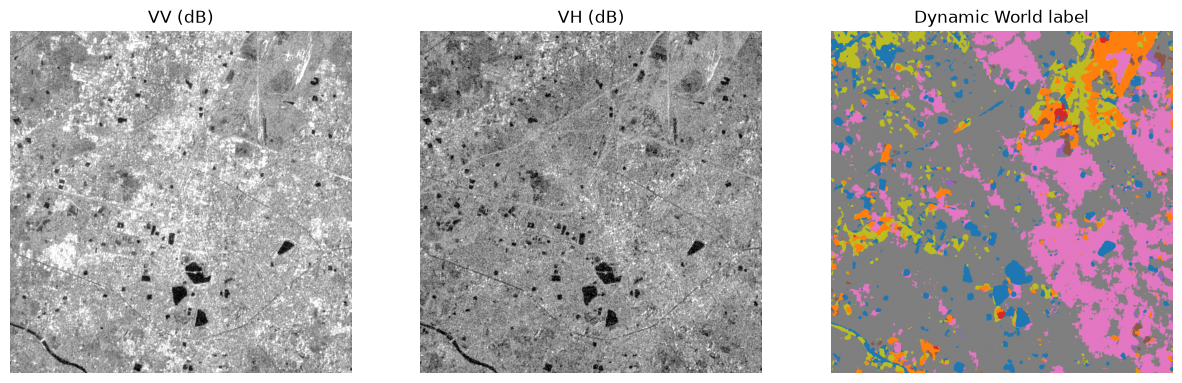

classes: {0: 'water', 1: 'trees', 2: 'grass', 3: 'flooded_vegetation', 4: 'crops', 5: 'shrub_and_scrub', 6: 'built', 7: 'bare', 8: 'snow_and_ice'}


In [9]:
SHOW = "raipur"
f = sorted(glob.glob(f"data/{SHOW}_{YEAR}-*.npz"))[0]
d = np.load(f)
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(d["radar"][0], cmap="gray", vmin=-25, vmax=0); ax[0].set_title("VV (dB)")
ax[1].imshow(d["radar"][1], cmap="gray", vmin=-30, vmax=-5); ax[1].set_title("VH (dB)")
im = ax[2].imshow(np.where(d["label"] == NODATA_LABEL, np.nan, d["label"]), cmap="tab10", vmin=0, vmax=9)
ax[2].set_title("Dynamic World label")
for a in ax: a.axis("off")
plt.show()
print("classes:", dict(enumerate(CLASSES)))

## 7. Bundle the dataset (five smaller zips, for the upload)

One huge zip is fragile to upload. This makes one zip per year of monthly files, plus one with the labels, WorldCover maps and `sites.csv`. They go into the `upload/` folder. On the server, each one is unpacked into `data/`.

In [ ]:
import zipfile

os.makedirs("upload", exist_ok=True)
years = sorted({YEAR, *EXTRA_YEARS})
parts = {f"monthly_{y}": sorted(glob.glob(f"data/*_{y}-*.npz")) for y in years}
parts["labels_and_sites"] = sorted(glob.glob("data/yearly/*.npz") + glob.glob("data/worldcover/*.npz") + ["data/sites.csv"])

summary = {}
for name, files in parts.items():
    out = f"upload/{name}.zip"
    with zipfile.ZipFile(out, "w", zipfile.ZIP_STORED) as z:    # the .npz files are already compressed, so just store them (fast)
        for f in files:
            z.write(f, arcname=os.path.relpath(f, "data"))
    with zipfile.ZipFile(out) as z:
        assert z.testzip() is None, f"{out} is damaged"        # the zip can be read back without errors
        assert len(z.namelist()) == len(files), out
    summary[name] = (len(files), os.path.getsize(out) / 1e9)

on_disk = len(glob.glob("data/*.npz")) + len(glob.glob("data/yearly/*.npz")) + len(glob.glob("data/worldcover/*.npz")) + 1
assert sum(n for n, _ in summary.values()) == on_disk, "some files are in no zip"
print(f"{'zip':24s}{'files':>8s}{'GB':>8s}")
for name, (n, gb) in summary.items():
    print(f"{name + '.zip':24s}{n:>8d}{gb:>8.2f}")
print(f"{'total':24s}{sum(n for n, _ in summary.values()):>8d}{sum(g for _, g in summary.values()):>8.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
names = list(summary)
ax[0].barh(names, [summary[n][1] for n in names], color="#2e86c1"); ax[0].set_xlabel("size (GB)"); ax[0].set_title("size of each zip")
ax[1].barh(names, [summary[n][0] for n in names], color="#27ae60"); ax[1].set_xlabel("files inside"); ax[1].set_title("number of files in each zip")
for a in ax:
    a.invert_yaxis()
plt.tight_layout()
plt.show()

## 8. Yearly labels (baseline label per site-year)

One label per site and year, with its confidence. It is the same calculation as the monthly label, just over 12 months, so `label_month` is reused. Saved to `data/yearly/<site>_<year>.npz`. The rule for combining monthly and yearly labels belongs to the training step, not here.

In [ ]:
import time
from concurrent.futures import ThreadPoolExecutor

os.makedirs("data/yearly", exist_ok=True)


def fetch_year(name, lat, lon, year):
    """Downloads and saves one yearly label. Runs in a worker thread."""
    out = f"data/yearly/{name}_{year}.npz"
    if os.path.exists(out):
        return None
    for attempt in range(3):
        try:
            grid, region = make_grid(lat, lon)
            lab = download(label_month(region, ee.Date.fromYMD(year, 1, 1), ee.Date.fromYMD(year + 1, 1, 1)), grid)    # (2, H, W): label, conf
            tmp = out + ".part"
            with open(tmp, "wb") as fh:
                np.savez_compressed(fh, label=lab[0].astype("uint8"), conf=lab[1].astype("float32"))
            os.replace(tmp, out)
            return f"{name} {year}: saved, share of pixels with no label {float((lab[0] == NODATA_LABEL).mean()):.3f}"
        except Exception as e:
            if attempt < 2 and ("429" in str(e) or "too many" in str(e).lower()):
                time.sleep(5 * (attempt + 1))
                continue
            return f"{name} {year}: FAILED ({type(e).__name__}: {e}); run the cell again to retry"


jobs = [(name, lat, lon, year) for name, lat, lon, role in SITES for year in years_for(role)]
with ThreadPoolExecutor(max_workers=WORKERS) as pool:
    for msg in pool.map(lambda job: fetch_year(*job), jobs):
        if msg:
            print(msg)

### Check the yearly labels

Shapes must match the monthly arrays, and every label must be a valid class or 255. Also prints each site's class shares, which is useful for the report's class-distribution section.

In [5]:
files = sorted(glob.glob("data/yearly/*.npz"))
for f in files:
    d = np.load(f)
    assert d["label"].shape == (SIZE_PX, SIZE_PX) and d["conf"].shape == (SIZE_PX, SIZE_PX), f
    assert set(np.unique(d["label"])) <= set(range(len(CLASSES))) | {NODATA_LABEL}, f
    shares = np.bincount(d["label"].ravel(), minlength=256) / d["label"].size
    top = {CLASSES[i]: round(float(shares[i]), 2) for i in range(len(CLASSES)) if shares[i] >= 0.01}
    print(os.path.basename(f), "| mean conf %.2f" % d["conf"].mean(), "| no label %.3f" % shares[NODATA_LABEL], "|", top)
print("yearly labels:", len(files), "of", sum(len(years_for(r)) for *_, r in SITES))

# picture: one row per site, one column per year. Colour = how sure Dynamic World is on average (yellow = more sure).
# A red X means a yearly label was planned but is missing.
years = sorted({YEAR, *EXTRA_YEARS})
names = [site[0] for site in SITES]
conf = np.full((len(names), len(years)), np.nan)
missing = []
for i, (name, lat, lon, role) in enumerate(SITES):
    for j, year in enumerate(years):
        if year not in years_for(role):
            continue
        f = f"data/yearly/{name}_{year}.npz"
        if os.path.exists(f):
            conf[i, j] = np.load(f)["conf"].mean()
        else:
            missing.append((i, j))
fig, ax = plt.subplots(figsize=(6, 0.3 * len(names) + 1.5))
im = ax.imshow(np.ma.masked_invalid(conf), cmap="viridis", vmin=0.2, vmax=0.65, aspect="auto")
for i, j in missing:
    ax.text(j, i, "X", color="red", ha="center", va="center", fontweight="bold")
ax.set_xticks(range(len(years))); ax.set_xticklabels(years)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
ax.set_title("yearly labels: mean confidence (red X = missing)")
plt.colorbar(im, ax=ax, label="mean confidence")
plt.tight_layout()
plt.show()
print("missing:", [f"{names[i]} {years[j]}" for i, j in missing] or "none")

NameError: name 'glob' is not defined

In [33]:
import shutil

shutil.make_archive("yearly", "zip", "data/yearly")   # tiny; upload next to dataset.zip
print("yearly.zip size (MB):", round(os.path.getsize("yearly.zip") / 1e6, 1))

yearly.zip size (MB): 56.0


## 9. Find rural sites automatically

Instead of checking places on a map by hand, search around a few rough starting points. Each base point is tried on a 3x3 grid about 28 km apart. For every candidate square, Earth Engine reports what the yearly Dynamic World label is made of (computed at a coarse 100 m scale, so nothing big is downloaded).

A candidate passes if it is not mostly built up and is well labelled. For each base point the most varied passing square (highest class diversity) wins. The winners print as lines ready to paste into `SITES`. Then glance at each winner on a satellite map, which takes minutes instead of an hour.

The screening label is Dynamic World itself, so a badly labelled square could slip through. That is what the quick look at the winners is for.

In [5]:
import itertools
import math

# rough starting points (name, lat, lon, role); the search moves around them
BASES = [   # anchors are town centres from OpenStreetMap's Nominatim (kwara_rural is still a rough guess); the grid search finds the countryside around them
    ("kwara_rural",    8.3000,   4.1000, "train"),
    ("kilombero",     -8.1321,  36.6848, "train"),   # Ifakara
    ("haor",          25.0671,  91.3986, "train"),   # Sunamganj
    ("chhattisgarh",  20.5326,  81.7156, "val"),     # Dhamtari
    ("e_zambia",     -13.6391,  32.6458, "val"),     # Chipata
    ("n_ghana",        9.4052,  -0.8424, "test"),    # Tamale
]

STEP = 0.25            # degrees between candidates, about 28 km
MAX_BUILT = 0.15       # a site passes only if less than this share is built up
MIN_LABELLED = 0.90    # ...and at least this share of the square has a label
year_start, year_end = ee.Date.fromYMD(YEAR, 1, 1), ee.Date.fromYMD(YEAR + 1, 1, 1)


def screen(lat, lon):
    """Class shares of the yearly label over the site's square, and the share of the square that has a label.
    Computed inside Earth Engine at 100 m, so there is nothing big to download."""
    _, region = make_grid(lat, lon)
    img = label_month(region, year_start, year_end).select("label")
    hist = img.reduceRegion(ee.Reducer.frequencyHistogram(), region, 100, maxPixels=1e9).get("label").getInfo()
    total = sum(hist.values())
    shares = {int(float(k)): v / total for k, v in hist.items()}
    assert abs(sum(shares.values()) - 1) < 1e-6
    return shares, 1 - shares.get(NODATA_LABEL, 0)


def search(bases):
    """Screens a 3x3 grid around every base point and returns all the candidate squares."""
    candidates = []
    for base, lat0, lon0, role in bases:
        for dy, dx in itertools.product((-1, 0, 1), repeat=2):
            lat, lon = lat0 + dy * STEP, lon0 + dx * STEP
            try:
                shares, labelled = screen(lat, lon)
            except Exception as e:
                print(f"{base} ({lat:.2f}, {lon:.2f}): FAILED ({type(e).__name__}); skipped")
                continue
            classes = {k: v for k, v in shares.items() if k != NODATA_LABEL}
            built = classes.get(CLASSES.index("built"), 0)
            diversity = -sum(p * math.log(p) for p in classes.values() if p > 0)   # higher = more evenly mixed classes
            candidates.append(dict(base=base, role=role, lat=round(lat, 4), lon=round(lon, 4),
                                   built=built, labelled=labelled, diversity=diversity, classes=classes))
        print(f"{base}: {sum(c['base'] == base for c in candidates)} candidates screened")
    return candidates


def pick_winners(bases, candidates, suffix=""):
    """For each base point, the passing candidate with the most varied classes. Prints lines ready to paste into SITES."""
    winners = []
    for base, lat0, lon0, role in bases:
        ok = [c for c in candidates if c["base"] == base and c["built"] <= MAX_BUILT and c["labelled"] >= MIN_LABELLED]
        if not ok:
            best = min((c for c in candidates if c["base"] == base), key=lambda c: c["built"], default=None)
            print(f"{base}: NO candidate passed. Lowest built share was",
                  f"{best['built']:.2f} at ({best['lat']}, {best['lon']})" if best else "n/a (all failed)")
            continue
        best = max(ok, key=lambda c: c["diversity"])
        winners.append(best)
        top = {CLASSES[k]: round(v, 2) for k, v in sorted(best["classes"].items(), key=lambda kv: -kv[1]) if v >= 0.02}
        print(f"{base}: {len(ok)}/9 passed; winner ({best['lat']}, {best['lon']}) built {best['built']:.2f} labelled {best['labelled']:.2f} {top}")
    print("\n# paste into SITES after a quick look at each on a satellite map:")
    for w in winners:
        print(f'    ("{w["base"]}{suffix}", {w["lat"]:>8}, {w["lon"]:>8}, "{w["role"]}"),')
    return winners

In [ ]:
# already done for these six anchors, their winners are in SITES; no need to run it again
candidates = search(BASES)
winners = pick_winners(BASES, candidates)

## 10. Rural squares around the dry-region towns

The six dry-region town centres are already in `SITES` (training sites). This finds a rural square near each, the same way as in section 9,
and prints lines to paste into `SITES`. They are named `<town>_rural`.

In [6]:
DRY_NAMES = ("dodoma", "kitui", "solapur", "pakokku", "khon_kaen", "adama")
DRY_ANCHORS = [s for s in SITES if s[0] in DRY_NAMES]
assert len(DRY_ANCHORS) == len(DRY_NAMES)

dry_candidates = search(DRY_ANCHORS)
dry_winners = pick_winners(DRY_ANCHORS, dry_candidates, suffix="_rural")

dodoma: 9 candidates screened
kitui: 9 candidates screened
solapur: 9 candidates screened
pakokku: 9 candidates screened
khon_kaen: 9 candidates screened
adama: 9 candidates screened
dodoma: 8/9 passed; winner (-5.9291, 35.4968) built 0.00 labelled 1.00 {'shrub_and_scrub': 0.71, 'water': 0.15, 'trees': 0.11, 'crops': 0.02}
kitui: 7/9 passed; winner (-1.6166, 38.0166) built 0.07 labelled 1.00 {'shrub_and_scrub': 0.44, 'trees': 0.36, 'crops': 0.13, 'built': 0.07}
solapur: 8/9 passed; winner (17.92, 76.1508) built 0.03 labelled 1.00 {'crops': 0.79, 'shrub_and_scrub': 0.16, 'built': 0.03}
pakokku: 8/9 passed; winner (21.0843, 94.8444) built 0.08 labelled 1.00 {'crops': 0.5, 'bare': 0.15, 'water': 0.13, 'built': 0.08, 'trees': 0.08, 'shrub_and_scrub': 0.05}
khon_kaen: 5/9 passed; winner (16.1804, 102.5856) built 0.09 labelled 1.00 {'trees': 0.32, 'crops': 0.32, 'shrub_and_scrub': 0.22, 'built': 0.09, 'water': 0.02, 'grass': 0.02}
adama: 7/9 passed; winner (8.294, 39.0205) built 0.01 labelle

## 11. A second opinion on the labels: ESA WorldCover

Dynamic World is a model's guess, so some of its labels are wrong. ESA WorldCover (2021, 10 m) is a second, independently made map. Where the two agree, a label is much more likely right. The training code can use this (`agree=True` in `lulc.py`): the yearly label is kept only where both sources agree.

WorldCover only exists for 2021 in Earth Engine, so for 2022 to 2025 it is a stable-land-cover check, not a same-year one. It is also partly built from Sentinel-1, so a map used as the independent check in the prototype's case study must be a different one.

WorldCover class numbers are converted to the Dynamic World indices used in our files. Moss and lichen have no counterpart and become ignore, like before.

In [6]:
# WorldCover value -> Dynamic World class index
WC_TO_DW = {10: 1, 20: 5, 30: 2, 40: 4, 50: 6, 60: 7, 70: 8, 80: 0, 90: 3, 95: 1}
#            tree shrub grass crops built bare snow water wetland->flooded vegetation, mangrove->trees; 100 (moss/lichen) -> 255


def worldcover(region):
    """ESA WorldCover (2021, 10 m) renumbered to the Dynamic World class indices; anything unmapped becomes 255."""
    wc = ee.ImageCollection("ESA/WorldCover/v200").first().select("Map")
    return wc.remap(list(WC_TO_DW), list(WC_TO_DW.values()), NODATA_LABEL).unmask(NODATA_LABEL).rename("label")


os.makedirs("data/worldcover", exist_ok=True)
for name, lat, lon, role in SITES:
    out = f"data/worldcover/{name}.npz"
    if os.path.exists(out):
        continue
    try:
        grid, region = make_grid(lat, lon)
        lab = download(worldcover(region), grid)[0].astype("uint8")
        tmp = out + ".part"
        with open(tmp, "wb") as fh:
            np.savez_compressed(fh, label=lab)
        os.replace(tmp, out)
        print(f"{name}: saved")
    except Exception as e:
        print(f"{name}: FAILED ({type(e).__name__}: {e}); run the cell again to retry")

kisumu: saved
morogoro: saved
ilorin: saved
raipur: saved
mymensingh: saved
battambang: saved
mzuzu: saved
warangal: saved
bobo_dioulasso: saved
nashik: saved
kwara_rural: saved
kilombero: saved
haor: saved
chhattisgarh: saved
e_zambia: saved
n_ghana: saved
dodoma: saved
kitui: saved
solapur: saved
pakokku: saved
khon_kaen: saved
adama: saved
dodoma_rural: saved
kitui_rural: saved
solapur_rural: saved
pakokku_rural: saved
khon_kaen_rural: saved
adama_rural: saved


### How often the two sources agree

Both labels are converted to our 7 classes. For each site: the share of pixels where they agree. Overall: for each class Dynamic World names, how often WorldCover says the same. A low number for a class means the label for it is shaky, and a lot of pixels will be dropped when the filter is on.

In [7]:
from lulc import CLASSES as CLASSES7, REMAP

hits = np.zeros(len(CLASSES7)); seen = np.zeros(len(CLASSES7))
for name, lat, lon, role in SITES:
    yf, wf = f"data/yearly/{name}_{YEAR}.npz", f"data/worldcover/{name}.npz"
    if not (os.path.exists(yf) and os.path.exists(wf)):
        continue
    a, b = REMAP[np.load(yf)["label"]], REMAP[np.load(wf)["label"]]      # both in our 7 classes (255 = ignore)
    both = (a != 255) & (b != 255)
    print(f"{name:18s} agree on {(a == b)[both].mean():.2f} of the pixels both sources label")
    for c in range(len(CLASSES7)):
        seen[c] += (a == c).sum(); hits[c] += ((a == c) & (b == c)).sum()
print("\nwhen Dynamic World says ..., WorldCover says the same:")
for c, n in enumerate(CLASSES7):
    print(f"  {n:20s} {hits[c] / max(seen[c], 1):.2f}   ({int(seen[c]):,} pixels)")

kisumu             agree on 0.45 of the pixels both sources label
morogoro           agree on 0.52 of the pixels both sources label
ilorin             agree on 0.80 of the pixels both sources label
raipur             agree on 0.71 of the pixels both sources label
mymensingh         agree on 0.60 of the pixels both sources label
battambang         agree on 0.56 of the pixels both sources label
mzuzu              agree on 0.59 of the pixels both sources label
warangal           agree on 0.63 of the pixels both sources label
bobo_dioulasso     agree on 0.71 of the pixels both sources label
nashik             agree on 0.64 of the pixels both sources label
kwara_rural        agree on 0.59 of the pixels both sources label
kilombero          agree on 0.42 of the pixels both sources label
haor               agree on 0.53 of the pixels both sources label
chhattisgarh       agree on 0.74 of the pixels both sources label
e_zambia           agree on 0.59 of the pixels both sources label
n_ghana   

### The same thing as pictures

**Left:** each row is what Dynamic World says. The numbers in the row show what WorldCover says for those same pixels, so the diagonal (top left to bottom right) is agreement. A pale diagonal square means the two sources disagree about that class.
**Right:** one bar per site, red if the sources agree on less than half of the pixels.

The filter (`agree=True`) drops the filled pixels where they disagree, so a class with a pale diagonal square loses most of its filled pixels.

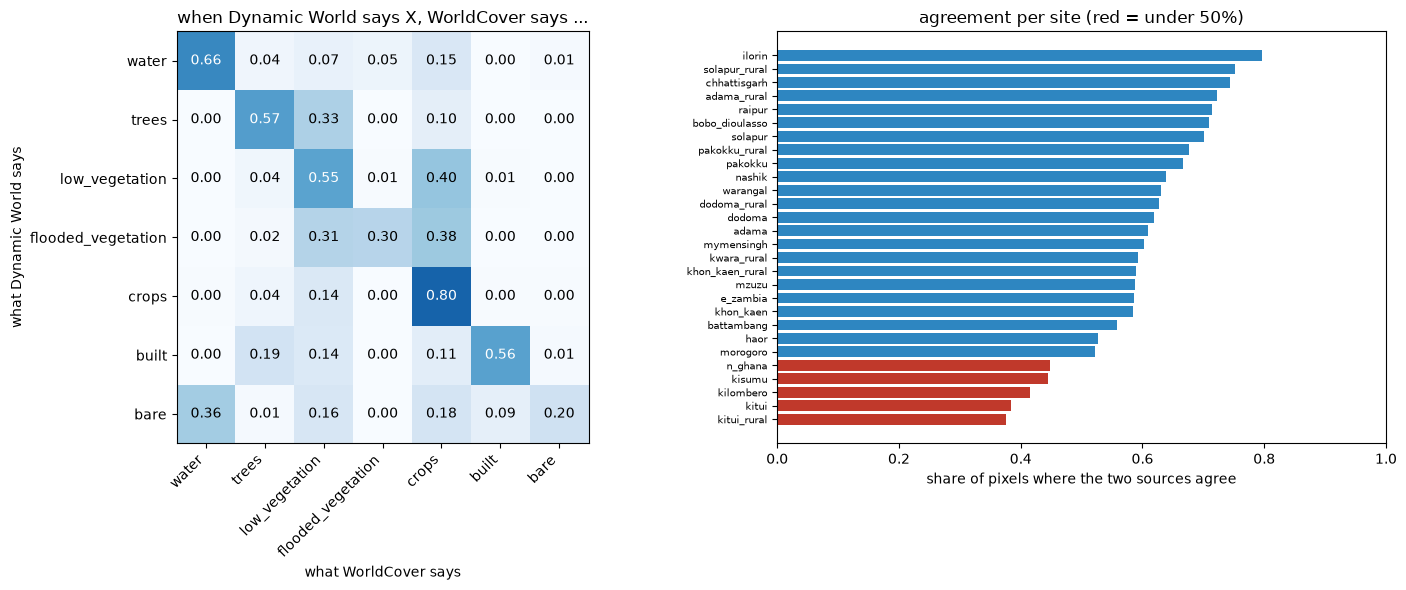

overall agreement 60%; the filter would drop about 40% of the filled (yearly) pixels


In [9]:
agree_pairs = {}                                    # site -> (Dynamic World yearly label, WorldCover label), both in our 7 classes
cm_dw_wc = np.zeros((len(CLASSES7), len(CLASSES7)))  # rows: what Dynamic World says, columns: what WorldCover says
for name, lat, lon, role in SITES:
    yf, wf = f"data/yearly/{name}_{YEAR}.npz", f"data/worldcover/{name}.npz"
    if not (os.path.exists(yf) and os.path.exists(wf)):
        continue
    a, b = REMAP[np.load(yf)["label"]], REMAP[np.load(wf)["label"]]
    agree_pairs[name] = (a, b)
    both = (a != 255) & (b != 255)
    cm_dw_wc += np.bincount(a[both].astype(int) * len(CLASSES7) + b[both].astype(int),
                            minlength=len(CLASSES7) ** 2).reshape(len(CLASSES7), len(CLASSES7))
site_agree = {n: float((a == b)[(a != 255) & (b != 255)].mean()) for n, (a, b) in agree_pairs.items()}

rows = cm_dw_wc / np.maximum(cm_dw_wc.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.1, 1]})
ax[0].imshow(rows, cmap="Blues", vmin=0, vmax=1)
ax[0].set_xticks(range(len(CLASSES7))); ax[0].set_xticklabels(CLASSES7, rotation=45, ha="right")
ax[0].set_yticks(range(len(CLASSES7))); ax[0].set_yticklabels(CLASSES7)
ax[0].set_xlabel("what WorldCover says"); ax[0].set_ylabel("what Dynamic World says")
ax[0].set_title("when Dynamic World says X, WorldCover says ...")
for i in range(len(CLASSES7)):
    for j in range(len(CLASSES7)):
        ax[0].text(j, i, f"{rows[i, j]:.2f}", ha="center", va="center", color="white" if rows[i, j] > 0.5 else "black")
order = sorted(site_agree, key=site_agree.get)
ax[1].barh(order, [site_agree[s] for s in order], color=["#c0392b" if site_agree[s] < 0.5 else "#2e86c1" for s in order])
ax[1].set_xlim(0, 1); ax[1].set_xlabel("share of pixels where the two sources agree")
ax[1].set_title("agreement per site (red = under 50%)"); ax[1].tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()
print(f"overall agreement {np.trace(cm_dw_wc) / cm_dw_wc.sum():.0%}; the filter would drop about "
      f"{1 - np.trace(cm_dw_wc) / cm_dw_wc.sum():.0%} of the filled (yearly) pixels")

### Where they disagree: the best and the worst site

Left: Dynamic World. Middle: WorldCover. Right: green = the two agree, red = they disagree.

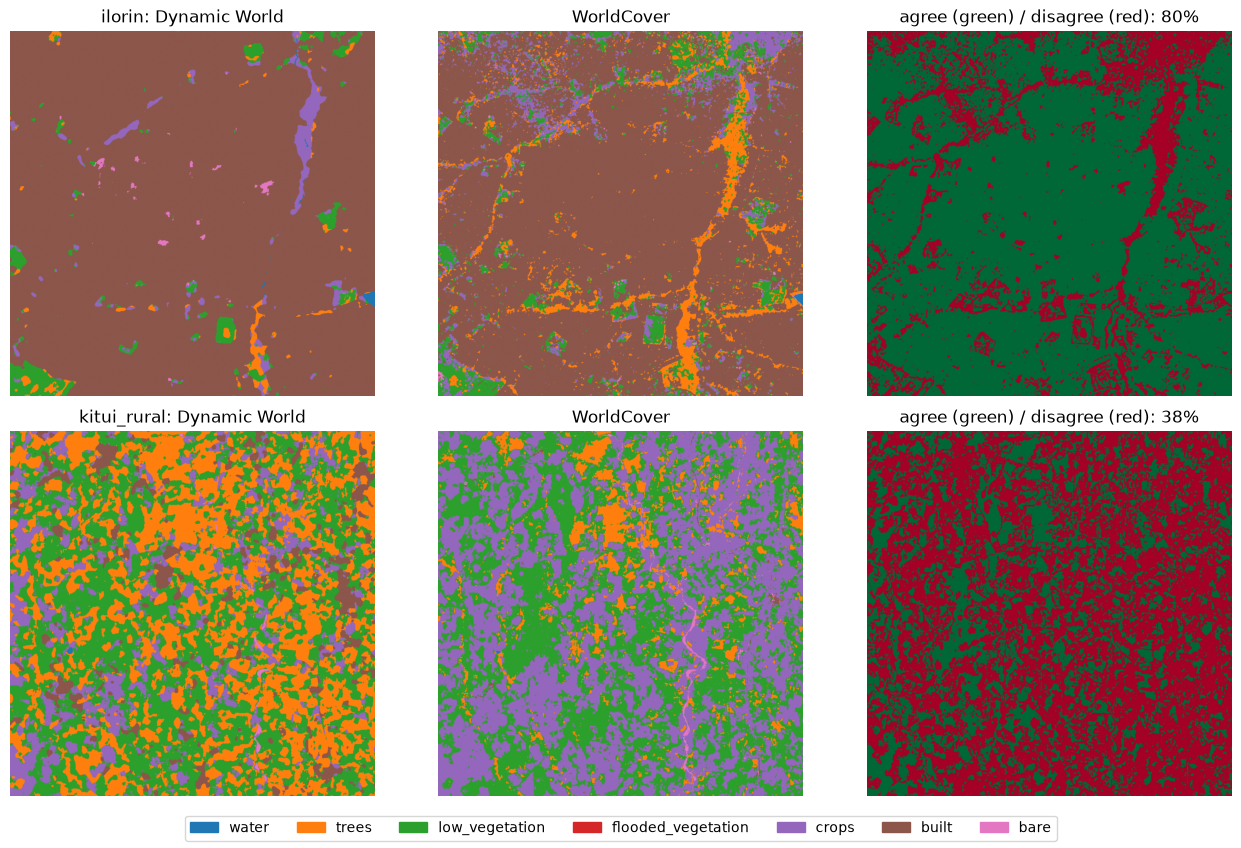

In [10]:
best, worst = max(site_agree, key=site_agree.get), min(site_agree, key=site_agree.get)
cmap = plt.get_cmap("tab10", 10)
fig, ax = plt.subplots(2, 3, figsize=(13, 8.5))
for r, s in enumerate((best, worst)):
    a, b = agree_pairs[s]
    ax[r, 0].imshow(np.ma.masked_equal(a, 255), cmap=cmap, vmin=0, vmax=9); ax[r, 0].set_title(f"{s}: Dynamic World")
    ax[r, 1].imshow(np.ma.masked_equal(b, 255), cmap=cmap, vmin=0, vmax=9); ax[r, 1].set_title("WorldCover")
    ax[r, 2].imshow(a == b, cmap="RdYlGn", vmin=0, vmax=1)
    ax[r, 2].set_title(f"agree (green) / disagree (red): {site_agree[s]:.0%}")
    for x in ax[r]:
        x.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=cmap(i)) for i in range(len(CLASSES7))]
fig.legend(handles, CLASSES7, loc="lower center", ncol=len(CLASSES7))
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

### Check: tiled download gives the same labels as a normal one

Earth Engine sometimes runs out of memory on a whole-year request, and `download` then splits it into tiles. This re-downloads one site you already have, in tiles, and compares it with the saved file. The right panel should be completely white (no differences).

kisumu 2024: tiled label matches the saved label on 100.0000% of the pixels


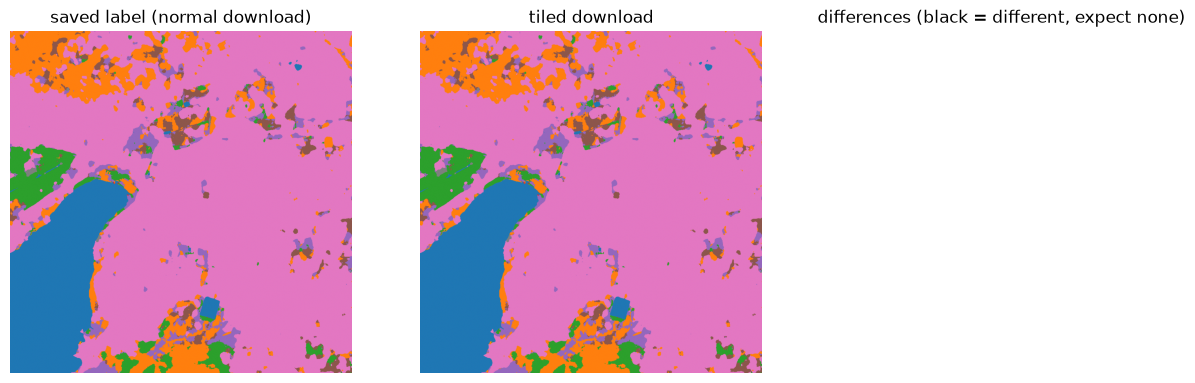

In [8]:
name, lat, lon, role = SITES[0]
grid, region = make_grid(lat, lon)
tiled = _download_tiled(label_month(region, ee.Date.fromYMD(YEAR, 1, 1), ee.Date.fromYMD(YEAR + 1, 1, 1)), grid, 2)
saved = np.load(f"data/yearly/{name}_{YEAR}.npz")
same = tiled[0].astype("uint8") == saved["label"]
print(f"{name} {YEAR}: tiled label matches the saved label on {same.mean():.4%} of the pixels")

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
cmap = plt.get_cmap("tab10", 10)
ax[0].imshow(np.ma.masked_equal(saved["label"], NODATA_LABEL), cmap=cmap, vmin=0, vmax=9); ax[0].set_title("saved label (normal download)")
ax[1].imshow(np.ma.masked_equal(tiled[0], NODATA_LABEL), cmap=cmap, vmin=0, vmax=9); ax[1].set_title("tiled download")
ax[2].imshow(~same, cmap="gray_r", vmin=0, vmax=1); ax[2].set_title("differences (black = different, expect none)")
for a in ax: a.axis("off")
plt.show()